In [1]:
import numpy as np
import pandas as pd
import tensorflow as tf
import random
import os
from tensorflow.keras.models import Sequential, clone_model, load_model
from tensorflow.keras.layers import LSTM, Dropout, Dense
from tensorflow.keras.optimizers import Adam, SGD
from tensorflow.keras.losses import BinaryCrossentropy
from tensorflow.keras.metrics import BinaryAccuracy, AUC
from tensorflow.keras.preprocessing.sequence import TimeseriesGenerator
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from sklearn.metrics import classification_report

c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\tensorflow\python\keras\engine\training_arrays_v1.py:37: UserWarning: A NumPy version >=1.23.5 and <2.3.0 is required for this version of SciPy (detected version 1.23.2)
  from scipy.sparse import issparse  # pylint: disable=g-import-not-at-top


In [2]:
from sklearn.metrics import (accuracy_score,
f1_score,
recall_score,
precision_score,
roc_auc_score,
auc
)
from sklearn.preprocessing import StandardScaler


In [3]:
# Set seed for reproducibility
seed = 42
np.random.seed(seed)
tf.random.set_seed(seed)
random.seed(seed)

In [4]:
# Load the dataset
data_x = pd.read_csv('X_cma.csv')
data_y = pd.read_csv('y_cma.csv')

In [5]:
# Remove the 'Unnamed: 0' column if it exists
if 'Unnamed: 0' in data_x.columns:
    data_x = data_x.drop(columns=['Unnamed: 0'])
if 'Unnamed: 0' in data_y.columns:
    data_y = data_y.drop(columns=['Unnamed: 0'])

In [6]:
# Convert to numpy arrays
X = data_x.values
y = data_y['Target'].values

In [7]:
# Use StandardScaler to scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [8]:
X_train,X_test = X[0:600],X[779:780]
y_train, y_test= y[0:600],y[779:780]

# Output the training and test data size
print(f"Train and Test Size {len(X_train)}, {len(X_test)}")

Train and Test Size 600, 1


In [9]:
c = np.bincount(y_train)
c

array([141, 459], dtype=int64)

In [10]:
# Define custom class weight function
def cwts(dfs):
    c0, c1 = np.bincount(dfs)
    w0 = (1 / c0) * (len(dfs)) / 2
    w1 = (1 / c1) * (len(dfs)) / 2
    return {0: w0, 1: w1}

In [11]:
# Calculate class weights
class_weight = cwts(y_train)

# Check the class weights
class_weight[0] * c[0], class_weight[1] * c[1]

print(class_weight)

{0: 2.127659574468085, 1: 0.6535947712418301}


In [12]:
# Sequence length for training
seqlen = 10
# Number of features
numfeat = X_train.shape[1]

# Generate sequence input for the training dataset
train_generator = TimeseriesGenerator(X_train, y_train, length=seqlen, batch_size=32)


In [13]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dropout, Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import BinaryCrossentropy
from tensorflow.keras.metrics import BinaryAccuracy, AUC

def create_model(hu=15, lookback=10, features=1):
    
    tf.keras.backend.clear_session()   

    # Instantiate the model
    model = Sequential()
    
    # Add LSTM layer
    model.add(LSTM(units=hu, input_shape=(lookback, features), activation='relu', return_sequences=False, name='LSTM1'))
    # Add Dropout layer
    model.add(Dropout(0.4, name='Dropout1'))
    # Add Dense output layer
    model.add(Dense(units=1, activation='sigmoid', name='Output'))             
    
    # Specify optimizer
    opt = Adam(learning_rate=0.001, epsilon=1e-08, decay=0.0)       
    
    # Model compilation
    model.compile(optimizer=opt, 
                  loss=BinaryCrossentropy(), 
                  metrics=[BinaryAccuracy(name='accuracy', threshold=0.5), AUC()])

    return model


In [14]:
# Create the model
model = create_model(hu=15, lookback=seqlen, features=numfeat)

model.summary()

c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\optimizers\base_optimizer.py:33: UserWarning: Argument `decay` is no longer supported and will be ignored.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ LSTM1 (LSTM)                    │ (None, 15)             │        11,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout1 (Dropout)              │ (None, 15)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output (Dense)                  │ (None, 1)              │            16 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,536 (45.06 KB)

 Trainable params: 11,536 (45.06 KB)

 Non-trainable params: 0 (0.00 B)

In [15]:
# Create path to save the results
from pathlib import Path

results_path = Path('results', 'lstm_time_series')
if not results_path.exists():
    results_path.mkdir(parents=True)

In [16]:
model_path = (results_path / 'model.keras').as_posix()

my_callbacks = [
    EarlyStopping(patience=10, monitor='loss', mode='min', verbose=1, restore_best_weights=True),
    ModelCheckpoint(filepath=model_path, verbose=1, monitor='loss', save_best_only=True)
]

In [17]:
print(X_train)

[[-3.49691100e-03 -5.33408200e-03  5.10753300e-03 ...  1.09040937e+02
   6.42140280e-02 -8.88319120e-02]
 [-8.18701200e-03 -6.84308400e-03  5.16584300e-03 ...  1.09156697e+02
   5.64940690e-02 -9.01883990e-02]
 [-4.12131600e-03  4.20575200e-03  5.52355100e-03 ...  1.09299611e+02
   6.81797520e-02 -9.75465580e-02]
 ...
 [ 1.53709000e-04  1.55921000e-04  1.93519200e-03 ...  1.17816119e+02
   5.54598190e-02 -2.99892380e-02]
 [-9.13393000e-04  6.16341000e-04 -1.11191300e-03 ...  1.17711573e+02
   6.35024740e-02 -3.05369770e-02]
 [ 1.64603300e-03  2.26945400e-03  8.88210000e-04 ...  1.17674960e+02
   7.05297630e-02 -3.22394310e-02]]


In [18]:
# Fit the model
model.fit(train_generator,
          epochs= 30, 
          verbose=1, 
          callbacks=my_callbacks, 
          shuffle=False,
          class_weight=class_weight)

Epoch 1/30


 1/19 ━━━━━━━━━━━━━━━━━━━━ 23s 1s/step - accuracy: 0.7812 - auc: 0.0000e+00 - loss: 19.2325
Epoch 1: loss improved from inf to 32.50513, saving model to results/lstm_time_series/model.keras
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.5005 - auc: 0.5789 - loss: 43.2898    
Epoch 2/30
 1/19 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.0000e+00 - auc: 0.0000e+00 - loss: 1.4805
Epoch 2: loss improved from 32.50513 to 0.68683, saving model to results/lstm_time_series/model.keras
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5126 - auc: 0.4750 - loss: 0.9530         


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 3/30
 1/19 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.0000e+00 - auc: 0.0000e+00 - loss: 1.4829
Epoch 3: loss did not improve from 0.68683
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5126 - auc: 0.4750 - loss: 0.9538         
Epoch 4/30
 1/19 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.0000e+00 - auc: 0.0000e+00 - loss: 1.4839
Epoch 4: loss did not improve from 0.68683
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5126 - auc: 0.4750 - loss: 0.9542         
Epoch 5/30
 1/19 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.0000e+00 - auc: 0.0000e+00 - loss: 1.4847
Epoch 5: loss did not improve from 0.68683
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5126 - auc: 0.4750 - loss: 0.9544         
Epoch 6/30
 1/19 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.0000e+00 - auc: 0.0000e+00 - loss: 1.4854
Epoch 6: loss did not improve from 0.68683
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5126 - auc: 0.4362 - loss: 0.9547         
Epoch 7/30
 1/19

In [19]:
# Manually create a batch for the single test sample
X_test_batch = np.expand_dims(X_test, axis=0)

In [20]:
# Predict on the single test sample
prediction = model.predict(X_test_batch)
print(f'Test Prediction: {prediction[0][0]:.2f}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step
Test Prediction: 0.50


In [21]:
# Evaluate with the training set
y_true = y_train[-(len(X_train)-seqlen):]
y_pred_probs = model.predict(train_generator)  # Predicted probabilities
y_pred = (y_pred_probs > 0.5).astype(int)  # Predicted classes

19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step


In [22]:
# Calculate evaluation metrics
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred)
recall = recall_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)
roc_auc = roc_auc_score(y_true, y_pred_probs)

In [23]:
print(f'Training Accuracy: {accuracy:.2f}')
print(f'Training Precision: {precision:.2f}')
print(f'Training Recall: {recall:.2f}')
print(f'Training F1 Score: {f1:.2f}')
print(f'Training ROC AUC: {roc_auc:.2f}')

Training Accuracy: 0.77
Training Precision: 0.77
Training Recall: 1.00
Training F1 Score: 0.87
Training ROC AUC: 0.50


In [24]:
# Binary classification
y_pred_cm = np.where(y_pred > 0.5, 1, 0)

In [25]:
from sklearn.metrics import (classification_report,
confusion_matrix
)

In [26]:
# Determine confusion matrix
cm = confusion_matrix(y_true, y_pred_cm)

In [27]:
# Plotting
import matplotlib.pyplot as plt

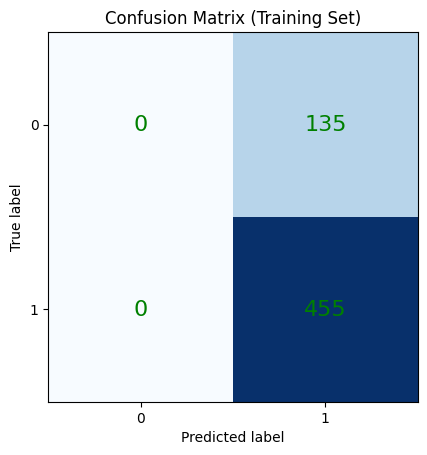

In [28]:
# Plot the confusion matrix
fig, ax = plt.subplots()
ax.imshow(cm, cmap=plt.cm.Blues)
ax.grid(False)

for i in range(cm.shape[0]): # Add number annotations for each cell
    for j in range(cm.shape[1]):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="green", fontsize=16)

# Add labels and title
plt.title('Confusion Matrix (Training Set)')
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.xticks(np.arange(2), [0, 1])
plt.yticks(np.arange(2), [0, 1])

plt.show()

In [29]:
# Classification report
print(classification_report(y_true, y_pred_cm))

              precision    recall  f1-score   support

           0       0.00      0.00      0.00       135
           1       0.77      1.00      0.87       455

    accuracy                           0.77       590
   macro avg       0.39      0.50      0.44       590
weighted avg       0.59      0.77      0.67       590



c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1517: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1517: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:1517: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, mo

In [30]:
from sklearn.metrics import (precision_recall_curve,
roc_curve,
RocCurveDisplay,
ConfusionMatrixDisplay
)

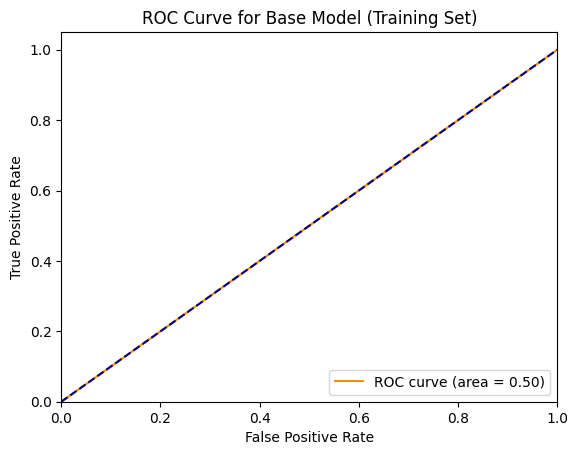

In [31]:
# Determine AUC
fpr, tpr, thresholds = roc_curve(y_true, y_pred)
roc_auc = auc(fpr, tpr)

# Plot ROC curve
plt.figure()
plt.plot(fpr, tpr, color='darkorange', label='ROC curve (area = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve for Base Model (Training Set)')
plt.legend(loc="lower right")
plt.show()

In [32]:
# Manually create a batch for the single test sample
X_test_batch = np.expand_dims(X_test, axis=0)

# Predict on the single test sample
prediction = model.predict(X_test_batch)
print(f'Test Prediction: {prediction[0][0]:.2f}')

# Evaluate with the test set
y_true_test = y_test  # Use the single true value in y_test
y_pred_test_probs = prediction  # Use prediction directly as y_pred_probs

# Binary classification
y_pred_test_cm = (y_pred_test_probs > 0.5).astype(int)

# Determine confusion matrix
cm_test = confusion_matrix(y_true_test, y_pred_test_cm)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step
Test Prediction: 0.50


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:395: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


c:\Users\tonfo\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\metrics\_classification.py:395: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


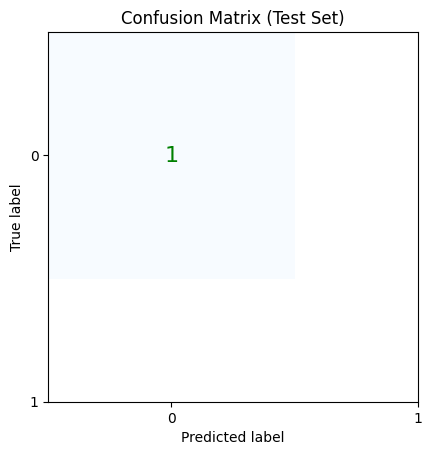

In [33]:
# Evaluate with the test set
y_true_test = y_test  # Use the single true value in y_test
y_pred_test_probs = prediction  # Use prediction directly as y_pred_probs

# Binary classification on test set
y_pred_test_cm = (y_pred_test_probs > 0.5).astype(int)

# Determine confusion matrix for test set
cm_test = confusion_matrix(y_true_test, y_pred_test_cm)

# Plot the confusion matrix for the test set
fig, ax = plt.subplots()
ax.imshow(cm_test, cmap=plt.cm.Blues)
ax.grid(False)

for i in range(cm_test.shape[0]): # Add number annotations for each cell
    for j in range(cm_test.shape[1]):
        ax.text(j, i, cm_test[i, j], ha="center", va="center", color="green", fontsize=16)

# Add labels and title
plt.title('Confusion Matrix (Test Set)')
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.xticks(np.arange(2), [0, 1])
plt.yticks(np.arange(2), [0, 1])

plt.show()

In [34]:
# Print classification report for test set
print("Classification Report for Test Set")
print(classification_report(y_true_test, y_pred_test_cm))

Classification Report for Test Set
              precision    recall  f1-score   support

           1       1.00      1.00      1.00         1

    accuracy                           1.00         1
   macro avg       1.00      1.00      1.00         1
weighted avg       1.00      1.00      1.00         1



In [35]:
model.save('model_CMA.h5')